# MAFIA: maximal frequent itemsets and association rules

We mine maximal patterns from the same 437 state-year profiles used for FP-Growth. We first show the baseline and exploratory results, then examine what maximal unions retain or omit and verify the actual search mechanisms. Every plot is generated in its own cell and saved at 300 dpi.

MFIs are itemsets, not rules. We interpret the assignment's “maximal association rules (MFIs)” as maximal frequent itemsets plus rules derived from their unions, using recounted subset supports. These are not necessarily all association rules. See the [methodology report](../report/mafia.md).

## Load the shared transactions

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/prison-mpl")
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from src.mining.fp_growth import load_transactions
from src.mining.mafia import mafia, run_mafia, serialize_maximal, validate_maximal, maximal_union_rules
sns.set_theme(style="whitegrid")
rows, matrix = load_transactions(ROOT)
transactions = [row["items"] for row in rows]
print(f"{len(rows)} state-year transactions; {len(matrix.columns)} items; five items per transaction.")
display(pd.DataFrame(rows).head())

437 state-year transactions; 15 items; five items per transaction.


,profile_id,state,year,items
0,Andaman & Nicobar Islands|2001,Andaman & Nicobar Islands,2001,"[age_18_30_share=lower_tertile, female_share=l..."
1,Andaman & Nicobar Islands|2002,Andaman & Nicobar Islands,2002,"[age_18_30_share=middle_tertile, female_share=..."
2,Andaman & Nicobar Islands|2003,Andaman & Nicobar Islands,2003,"[age_18_30_share=upper_tertile, female_share=l..."
3,Andaman & Nicobar Islands|2004,Andaman & Nicobar Islands,2004,"[age_18_30_share=upper_tertile, female_share=l..."
4,Andaman & Nicobar Islands|2005,Andaman & Nicobar Islands,2005,"[age_18_30_share=lower_tertile, female_share=l..."


## MAFIA search and baseline

The source implements the head/tail search from [the original paper](https://www.cs.cornell.edu/johannes/papers/2001/icde2001-mafia.pdf): vertical bitmaps, parent-equivalence pruning, leftmost FHUT, HUTMFI, ascending-support reordering and a maintained maximal-candidate repository. It does not call another frequent-itemset miner to obtain the MAFIA output. Python integer bitmaps omit the paper's adaptive relative-compression optimization. The exact implementation and test mapping are documented in the report.

The baseline remains 10% support (at least 44 profiles) and 70% confidence.

In [2]:
baseline, counters = mafia(transactions, min_support=0.10)
counts, extension_checks = validate_maximal(baseline, transactions, min_support=0.10)
display(serialize_maximal(baseline, len(rows)).head(20))
print("Baseline maximal itemsets:", len(baseline))
print("Search counters:", counters)
baseline_rules, support_cache = maximal_union_rules(baseline, transactions, confidence=0.70)
display(baseline_rules)
print("Baseline rules:", len(baseline_rules))

,items,length,support_count,support
0,"[""illiterate_share=lower_tertile"", ""occupancy_...",2,87,0.199085
1,"[""female_share=upper_tertile"", ""occupancy_rati...",2,73,0.167048
2,"[""occupancy_ratio=within_capacity"", ""undertria...",2,70,0.160183
3,"[""age_18_30_share=upper_tertile"", ""undertrial_...",2,69,0.157895
4,"[""age_18_30_share=middle_tertile"", ""female_sha...",2,68,0.155606
5,"[""occupancy_ratio=over_100_to_150pct"", ""undert...",2,68,0.155606
6,"[""female_share=lower_tertile"", ""illiterate_sha...",2,66,0.151030
7,"[""female_share=middle_tertile"", ""illiterate_sh...",2,66,0.151030
8,"[""age_18_30_share=upper_tertile"", ""occupancy_r...",2,65,0.148741
9,"[""age_18_30_share=middle_tertile"", ""undertrial...",2,64,0.146453


Baseline maximal itemsets: 60
Search counters: {'nodes': 76, 'bitmap_intersections': 261, 'infrequent_extensions': 186, 'pep_items': 0, 'fhut_prunes': 1, 'hutmfi_prunes': 1, 'dynamic_reorder_nodes': 14, 'candidate_insertions': 60, 'dominated_candidates_removed': 0, 'max_recursion_depth': 2, 'fhut_sibling_branches_skipped': 0, 'hutmfi_tail_items_skipped': 0}


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,leverage


Baseline rules: 0


**Finding:** The baseline contains 60 maximal pairs versus 75 complete frequent itemsets. Its largest-support maximal pair joins lower-tertile illiterate share with within-capacity occupancy: 87 profiles (19.91%). No rule reaches 70% confidence. This intentionally empty rule result agrees with FP-Growth.

## Compare support settings and itemset lengths

In [3]:
summary = run_mafia(ROOT)
TABLES = ROOT / "results/tables/mafia"
PLOTS = ROOT / "results/plots/mafia"
PLOTS.mkdir(parents=True, exist_ok=True)
comparison = pd.read_csv(TABLES / "parameter_comparison.csv")
lengths = pd.read_csv(TABLES / "maximal_length_distribution.csv")
unique_supports = comparison.drop_duplicates("min_support")
display(comparison[["min_support", "min_confidence", "fp_frequent_itemsets", "maximal_itemsets", "fp_all_rules", "maximal_union_rules", "omitted_fp_rules"]])

,min_support,min_confidence,fp_frequent_itemsets,maximal_itemsets,fp_all_rules,maximal_union_rules,omitted_fp_rules
0,0.05,0.6,166,87,16,15,1
1,0.05,0.7,166,87,4,4,0
2,0.05,0.8,166,87,0,0,0
3,0.10,0.6,75,60,1,1,0
4,0.10,0.7,75,60,0,0,0
5,0.10,0.8,75,60,0,0,0
6,0.15,0.6,23,12,0,0,0
7,0.15,0.7,23,12,0,0,0
8,0.15,0.8,23,12,0,0,0
9,0.20,0.6,15,15,0,0,0


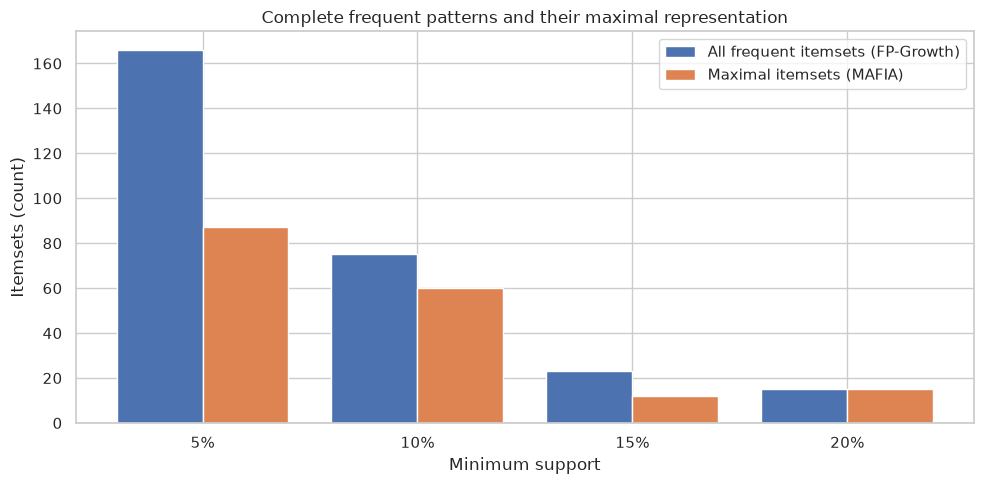

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(unique_supports))
ax.bar(positions - .2, unique_supports.fp_frequent_itemsets, width=.4, label="All frequent itemsets (FP-Growth)")
ax.bar(positions + .2, unique_supports.maximal_itemsets, width=.4, label="Maximal itemsets (MAFIA)")
ax.set_xticks(positions, [f"{value:.0%}" for value in unique_supports.min_support])
ax.set_xlabel("Minimum support")
ax.set_ylabel("Itemsets (count)")
ax.set_title("Complete frequent patterns and their maximal representation")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "frequent_vs_maximal.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

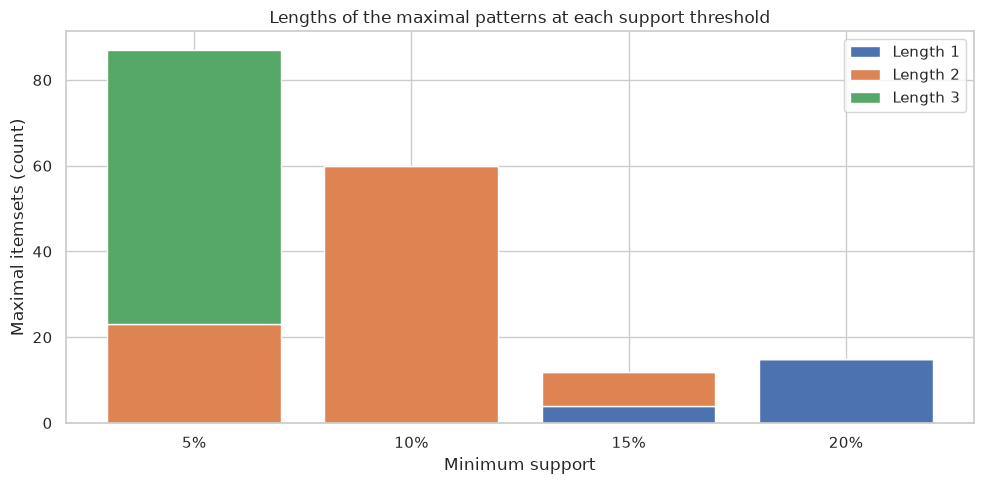

In [5]:
length_table = lengths.pivot(index="min_support", columns="length", values="maximal_itemsets").fillna(0)
fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(length_table))
for length in length_table.columns:
    values = length_table[length].to_numpy()
    ax.bar(np.arange(len(length_table)), values, bottom=bottom, label=f"Length {int(length)}")
    bottom += values
ax.set_xticks(np.arange(len(length_table)), [f"{value:.0%}" for value in length_table.index])
ax.set_xlabel("Minimum support")
ax.set_ylabel("Maximal itemsets (count)")
ax.set_title("Lengths of the maximal patterns at each support threshold")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "maximal_lengths.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Finding:** At 5% support there are 87 MFIs: 23 pairs and 64 triples, compared with 166 complete frequent sets. At 15% support there are 12 MFIs; at 20%, 15 singleton MFIs. This increase is valid: as supersets become infrequent, previously nonmaximal subsets can become maximal. Maximal does not mean highest-support or globally longest.

## Exploratory rules and exact support recounting

In [6]:
exploratory = pd.read_csv(TABLES / "exploratory_maximal_union_rules.csv")
recounted = pd.read_csv(TABLES / "exploratory_recounted_supports.csv")
display(exploratory)
print("Distinct supports recounted for union partitions:", len(recounted))
display(recounted.head(15))

,antecedents,consequents,antecedent_support,consequent_support,support,confidence,lift,leverage,antecedent_count,consequent_count,support_count,antecedent_length,consequent_length,covered_states,covered_years
0,"[""female_share=middle_tertile"", ""occupancy_rat...","[""illiterate_share=upper_tertile""]",0.086957,0.334096,0.064073,0.736842,2.205479,0.035021,38,146,28,2,1,8,12
1,"[""female_share=upper_tertile"", ""illiterate_sha...","[""occupancy_ratio=within_capacity""]",0.105263,0.411899,0.077803,0.739130,1.794444,0.034445,46,180,34,2,1,8,13
2,"[""illiterate_share=lower_tertile"", ""undertrial...","[""occupancy_ratio=within_capacity""]",0.102975,0.411899,0.075515,0.733333,1.780370,0.033100,45,180,33,2,1,8,12
3,"[""age_18_30_share=upper_tertile"", ""illiterate_...","[""occupancy_ratio=within_capacity""]",0.128146,0.411899,0.093822,0.732143,1.777480,0.041038,56,180,41,2,1,10,13


Distinct supports recounted for union partitions: 166


,items,support_count,support
0,"[""age_18_30_share=lower_tertile""]",146,0.334096
1,"[""age_18_30_share=middle_tertile""]",145,0.331808
2,"[""age_18_30_share=upper_tertile""]",146,0.334096
3,"[""female_share=lower_tertile""]",146,0.334096
4,"[""female_share=middle_tertile""]",145,0.331808
5,"[""female_share=upper_tertile""]",146,0.334096
6,"[""illiterate_share=lower_tertile""]",147,0.336384
7,"[""illiterate_share=middle_tertile""]",144,0.329519
8,"[""illiterate_share=upper_tertile""]",146,0.334096
9,"[""occupancy_ratio=over_100_to_150pct""]",160,0.366133


At 5% support / 70% confidence, four rules qualify and match Phase 6's four exploratory rules. We enumerate all nonempty proper antecedents within each maximal union and recount both sides from the original transactions. Across all these partitions, the cache contains 166 supports—every frequent set in this small cohort. A smaller maximal-itemset output therefore does not imply the same reduction in rule-generation support storage.

1. **female_share=middle_tertile + occupancy_ratio=over_150pct → illiterate_share=upper_tertile.** The maximal union occurs in 28 profiles (6.41% support); the antecedent occurs in 38 profiles. Recounted confidence is 73.68% and lift is 2.205. The joint pattern spans 8 jurisdictions and 12 years. This describes pooled profile co-occurrence, not individual outcomes or a causal relationship.

2. **female_share=upper_tertile + illiterate_share=lower_tertile → occupancy_ratio=within_capacity.** The maximal union occurs in 34 profiles (7.78% support); the antecedent occurs in 46 profiles. Recounted confidence is 73.91% and lift is 1.794. The joint pattern spans 8 jurisdictions and 13 years. This describes pooled profile co-occurrence, not individual outcomes or a causal relationship.

3. **illiterate_share=lower_tertile + undertrial_share=upper_tertile → occupancy_ratio=within_capacity.** The maximal union occurs in 33 profiles (7.55% support); the antecedent occurs in 45 profiles. Recounted confidence is 73.33% and lift is 1.780. The joint pattern spans 8 jurisdictions and 12 years. This describes pooled profile co-occurrence, not individual outcomes or a causal relationship.

4. **age_18_30_share=upper_tertile + illiterate_share=lower_tertile → occupancy_ratio=within_capacity.** The maximal union occurs in 41 profiles (9.38% support); the antecedent occurs in 56 profiles. Recounted confidence is 73.21% and lift is 1.777. The joint pattern spans 10 jurisdictions and 13 years. This describes pooled profile co-occurrence, not individual outcomes or a causal relationship.

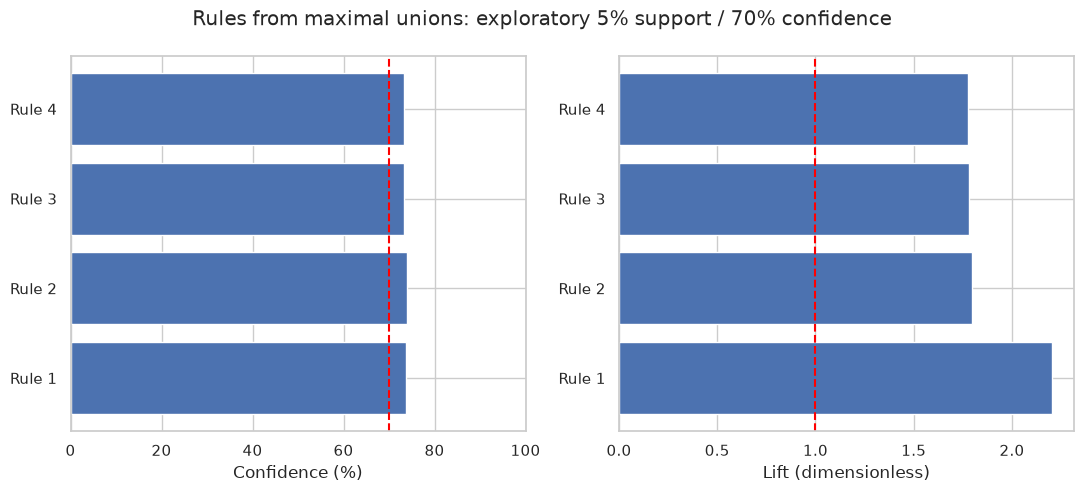

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
labels = [f"Rule {i+1}" for i in range(len(exploratory))]
axes[0].barh(labels, exploratory.confidence * 100)
axes[0].axvline(70, color="red", linestyle="--")
axes[0].set_xlim(0, 100)
axes[0].set_xlabel("Confidence (%)")
axes[1].barh(labels, exploratory.lift)
axes[1].axvline(1, color="red", linestyle="--")
axes[1].set_xlabel("Lift (dimensionless)")
fig.suptitle("Rules from maximal unions: exploratory 5% support / 70% confidence")
fig.tight_layout()
fig.savefig(PLOTS / "exploratory_rule_metrics.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## Which FP-Growth rule is omitted?

In [8]:
omitted = pd.read_csv(TABLES / "omitted_fp_rules.csv")
display(omitted)
print("Containing maximal triples:")
for items in json.loads(omitted.iloc[0].containing_maximal_itemsets):
    print(items)

,min_support,min_confidence,antecedents,consequents,antecedent_support,consequent_support,support,confidence,lift,leverage,antecedent_count,consequent_count,support_count,antecedent_length,consequent_length,covered_states,covered_years,containing_maximal_itemsets
0,0.05,0.6,"[""occupancy_ratio=over_150pct""]","[""illiterate_share=upper_tertile""]",0.221968,0.334096,0.141876,0.639175,1.913148,0.067718,97,146,62,1,1,13,13,"[[""age_18_30_share=middle_tertile"", ""illiterat..."


Containing maximal triples:
['age_18_30_share=middle_tertile', 'illiterate_share=upper_tertile', 'occupancy_ratio=over_150pct']
['female_share=lower_tertile', 'illiterate_share=upper_tertile', 'occupancy_ratio=over_150pct']
['female_share=middle_tertile', 'illiterate_share=upper_tertile', 'occupancy_ratio=over_150pct']
['illiterate_share=upper_tertile', 'occupancy_ratio=over_150pct', 'undertrial_share=upper_tertile']


**Finding:** At 5% support / 60% confidence, FP-Growth has 16 rules but maximal unions have 15. The omitted rule is occupancy above 150% → upper-tertile illiterate share: support 62/437 = 14.19%, confidence 62/97 = 63.92%, lift 1.913. Its pair union has four frequent triple extensions, so it is nonmaximal. Partitioning maximal unions alone cannot generate this rule; its omission is not an algorithm error.

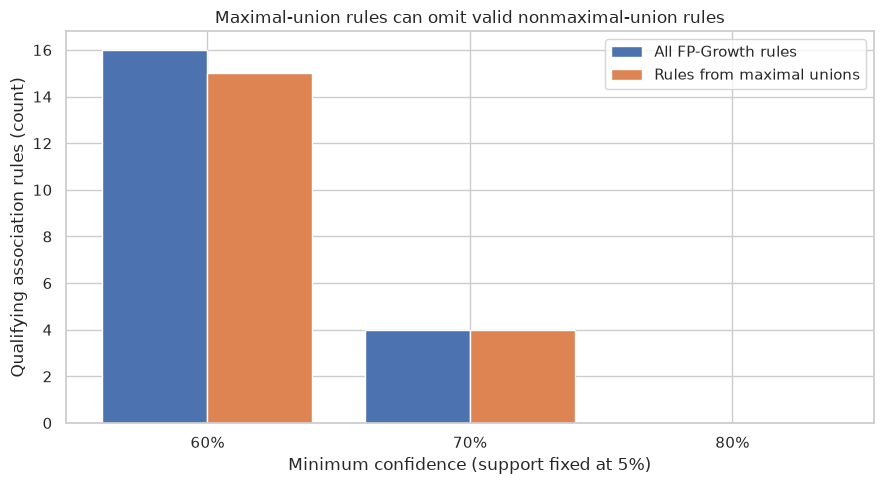

In [9]:
subset = comparison[np.isclose(comparison.min_support, .05)]
fig, ax = plt.subplots(figsize=(9, 5))
positions = np.arange(len(subset))
ax.bar(positions - .2, subset.fp_all_rules, width=.4, label="All FP-Growth rules")
ax.bar(positions + .2, subset.maximal_union_rules, width=.4, label="Rules from maximal unions")
ax.set_xticks(positions, [f"{value:.0%}" for value in subset.min_confidence])
ax.set_xlabel("Minimum confidence (support fixed at 5%)")
ax.set_ylabel("Qualifying association rules (count)")
ax.set_title("Maximal-union rules can omit valid nonmaximal-union rules")
ax.legend()
fig.tight_layout()
fig.savefig(PLOTS / "rule_family_coverage.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## Verify pruning and search work

,min_support,configuration,output_equivalent,nodes,bitmap_intersections,infrequent_extensions,pep_items,fhut_prunes,hutmfi_prunes,dynamic_reorder_nodes,candidate_insertions,dominated_candidates_removed,max_recursion_depth,fhut_sibling_branches_skipped,hutmfi_tail_items_skipped
0,0.05,full,True,167,446,280,0,25,14,56,87,0,3,0,0
1,0.05,without_pep,True,167,446,280,0,25,14,56,87,0,3,0,0
2,0.05,without_fhut,True,167,446,280,0,0,14,56,87,0,3,0,0
3,0.05,without_hutmfi,True,167,446,280,0,25,0,56,87,0,3,0,0
4,0.05,without_dynamic_order,True,167,512,346,0,17,10,0,87,0,3,0,0
5,0.05,plain_dfs_control,True,167,512,346,0,0,0,0,87,0,3,0,0
6,0.10,full,True,76,261,186,0,1,1,14,60,0,2,0,0
7,0.10,without_pep,True,76,261,186,0,1,1,14,60,0,2,0,0
8,0.10,without_fhut,True,76,261,186,0,0,1,14,60,0,2,0,0
9,0.10,without_hutmfi,True,76,261,186,0,1,0,14,60,0,2,0,0


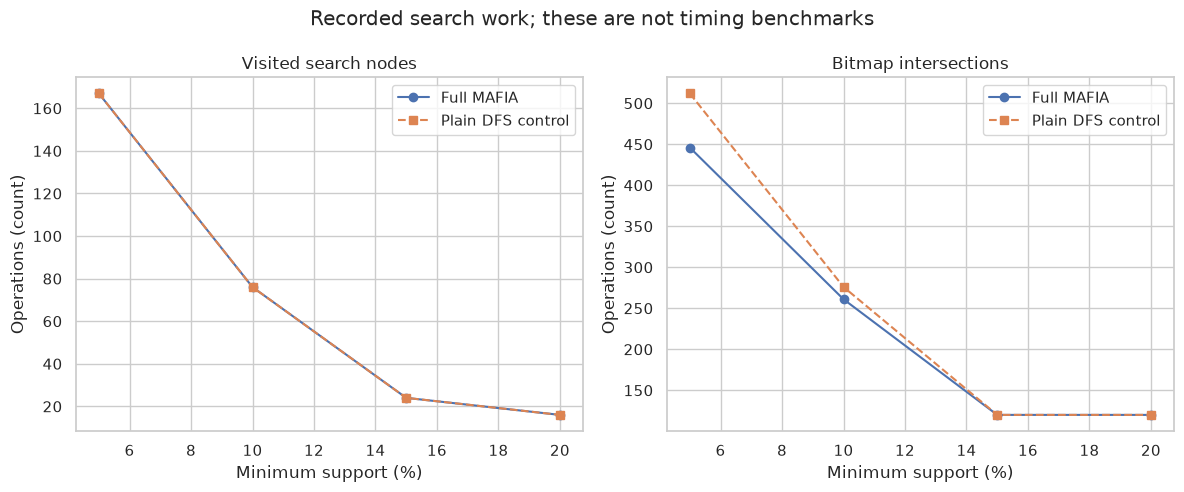

In [10]:
ablation = pd.read_csv(TABLES / "pruning_ablation.csv")
display(ablation)
assert ablation.output_equivalent.all()
full = ablation[ablation.configuration == "full"]
control = ablation[ablation.configuration == "plain_dfs_control"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, field, title in zip(axes, ["nodes", "bitmap_intersections"], ["Visited search nodes", "Bitmap intersections"]):
    ax.plot(full.min_support * 100, full[field], marker="o", label="Full MAFIA")
    ax.plot(control.min_support * 100, control[field], marker="s", linestyle="--", label="Plain DFS control")
    ax.set_xlabel("Minimum support (%)")
    ax.set_ylabel("Operations (count)")
    ax.set_title(title)
    ax.legend()
fig.suptitle("Recorded search work; these are not timing benchmarks")
fig.tight_layout()
fig.savefig(PLOTS / "search_work_counters.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

**Finding:** All 24 ablation settings preserve the corresponding MFI output. At 5%, full MAFIA and the plain DFS control both visit 167 nodes, but use 446 versus 512 intersections. PEP moves no items, and FHUT/HUTMFI skip no nonempty remaining branches/tails on these real transactions. Their event counters alone are not proof of saved node expansion. Dense fixtures exercise actual pruning. We do not claim runtime speedup from these counters.

## Validation and limitations

Each support setting passes exact frequency, complete maximality and one-item-extension checks, plus comparison against maximal sets derived independently from frozen FP-Growth outputs. All twelve rule settings agree with the corresponding FP rule subset and metrics. Forty seeded small fixtures test all 16 pruning/order combinations against exhaustive enumeration. A long-itemset fixture verifies PEP without exponential enumeration.

Repeated state-years, cohort-fitted bins and exploratory thresholds limit interpretation. MFIs lose subset supports and may omit rules from nonmaximal unions. Adaptive bitmap compression and specialized indexing are omitted, with no performance-parity claim. PySpark comparisons are documented in the separate Spark notebooks.

In [11]:
from src.preprocessing.cleaning import sha256
for item in summary["inputs"]:
    assert sha256(ROOT / item["file"]) == item["sha256"]
assert len(summary["validation"]) == 12
assert all(v["exact_frequency_and_maximality"] and v["complete_maximal_union_rule_equivalence"] for v in summary["validation"])
print("Verified unchanged inputs, complete MFIs and exact maximal-union rule equivalence.")

Verified unchanged inputs, complete MFIs and exact maximal-union rule equivalence.


## References

- [Original MAFIA paper](https://www.cs.cornell.edu/johannes/papers/2001/icde2001-mafia.pdf), particularly Figure 5 and Sections 3–4.
- [FP-Growth methodology](../report/fp_growth.md) and [transformation methodology](../report/data_transformation.md).